# Rossmann Store Sales — Phase 0: EDA

Goal: understand the business problem, target, and available data before any modeling. Uses `train.csv` and `store.csv` only — `test.csv` stays unseen until the final evaluation notebook.

In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.io as pio
pio.templates.default = "plotly_white"

pd.set_option("display.max_columns", 50)

# StateHoliday is explicitly cast to str on read (belt-and-suspenders alongside
# low_memory=False, which already forces single-pass, whole-column dtype inference).
train = pd.read_csv("train.csv", parse_dates=["Date"], low_memory=False, dtype={"StateHoliday": str})
store = pd.read_csv("store.csv")

print(train.shape, store.shape)
train.dtypes

(1017209, 9) (1115, 10)


Store                     int64
DayOfWeek                 int64
Date             datetime64[us]
Sales                     int64
Customers                 int64
Open                      int64
Promo                     int64
StateHoliday                str
SchoolHoliday             int64
dtype: object

## Data dictionary

**`train.csv`** (also `test.csv`, minus `Sales`/`Customers`, plus an `Id` column for submission):

| Column | Description |
|---|---|
| `Store` | Unique store ID (1-1115), join key with `store.csv` |
| `DayOfWeek` | Day of week, 1 = Monday ... 7 = Sunday |
| `Date` | Calendar date of the observation |
| `Sales` | Turnover for that store on that day — the prediction target |
| `Customers` | Number of customers that day — historical only, not in `test.csv` |
| `Open` | Whether the store was open (1) or closed (0) that day |
| `Promo` | Whether a store was running a one-day/short-term promotion that day |
| `StateHoliday` | `0` = none, `a` = public holiday, `b` = Easter holiday, `c` = Christmas |
| `SchoolHoliday` | Whether the (Store, Date) was affected by school closures |

**`store.csv`** (one row per store, static/slowly-changing attributes):

| Column | Description |
|---|---|
| `Store` | Unique store ID, join key with `train.csv`/`test.csv` |
| `StoreType` | Store model/category: a/b/c/d |
| `Assortment` | Product assortment level: a = basic, b = extra, c = extended |
| `CompetitionDistance` | Distance in meters to the nearest competitor store |
| `CompetitionOpenSinceMonth`/`Year` | Approximate month/year the nearest competitor opened |
| `Promo2` | Whether the store participates in Promo2, a recurring/continuing promotion (0/1) |
| `Promo2SinceWeek`/`Year` | ISO week/year the store started participating in Promo2 |
| `PromoInterval` | Comma-separated months when a new Promo2 round starts (e.g. `"Feb,May,Aug,Nov"`) |

In [2]:
print(store.head())
print()
store.info()
print()
print("missing values:\n", store.isna().sum())
print()
store.describe(include="all")

   Store StoreType Assortment  CompetitionDistance  CompetitionOpenSinceMonth  \
0      1         c          a               1270.0                        9.0   
1      2         a          a                570.0                       11.0   
2      3         a          a              14130.0                       12.0   
3      4         c          c                620.0                        9.0   
4      5         a          a              29910.0                        4.0   

   CompetitionOpenSinceYear  Promo2  Promo2SinceWeek  Promo2SinceYear  \
0                    2008.0       0              NaN              NaN   
1                    2007.0       1             13.0           2010.0   
2                    2006.0       1             14.0           2011.0   
3                    2009.0       0              NaN              NaN   
4                    2015.0       0              NaN              NaN   

     PromoInterval  
0              NaN  
1  Jan,Apr,Jul,Oct  
2  Jan,Apr,

<class 'pandas.DataFrame'>
RangeIndex: 1115 entries, 0 to 1114
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Store                      1115 non-null   int64  
 1   StoreType                  1115 non-null   str    
 2   Assortment                 1115 non-null   str    
 3   CompetitionDistance        1112 non-null   float64
 4   CompetitionOpenSinceMonth  761 non-null    float64
 5   CompetitionOpenSinceYear   761 non-null    float64
 6   Promo2                     1115 non-null   int64  
 7   Promo2SinceWeek            571 non-null    float64
 8   Promo2SinceYear            571 non-null    float64
 9   PromoInterval              571 non-null    str    
dtypes: float64(5), int64(2), str(3)
memory usage: 98.0 KB

missing values:
 Store                          0
StoreType                      0
Assortment                     0
CompetitionDistance            3
CompetitionOpenSinceMon

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
count,1115.00000,1115,1115,1112.000000,761.000000,761.000000,1115.000000,571.000000,571.000000,571
unique,NaN,4,3,NaN,NaN,NaN,NaN,NaN,NaN,3
top,NaN,a,a,NaN,NaN,NaN,NaN,NaN,NaN,"Jan,Apr,Jul,Oct"
freq,NaN,602,593,NaN,NaN,NaN,NaN,NaN,NaN,335
mean,558.00000,NaN,NaN,5404.901079,7.224704,2008.668857,0.512108,23.595447,2011.763573,NaN
std,322.01708,NaN,NaN,7663.174720,3.212348,6.195983,0.500078,14.141984,1.674935,NaN
min,1.00000,NaN,NaN,20.000000,1.000000,1900.000000,0.000000,1.000000,2009.000000,NaN
25%,279.50000,NaN,NaN,717.500000,4.000000,2006.000000,0.000000,13.000000,2011.000000,NaN
50%,558.00000,NaN,NaN,2325.000000,8.000000,2010.000000,1.000000,22.000000,2012.000000,NaN
75%,836.50000,NaN,NaN,6882.500000,10.000000,2013.000000,1.000000,37.000000,2013.000000,NaN


In [3]:
print("rows with CompetitionOpenSinceYear == 1900:", (store["CompetitionOpenSinceYear"] == 1900).sum())
print("Promo2==0 count matches Promo2SinceWeek nulls:",
      (store["Promo2"] == 0).sum(), "vs", store["Promo2SinceWeek"].isna().sum())

rows with CompetitionOpenSinceYear == 1900:

 1
Promo2==0 count matches Promo2SinceWeek nulls: 544 vs 544


**`store.csv` findings:** 1,115 stores, 4 `StoreType` values (a/b/c/d), 3 `Assortment` values (a/b/c). Missingness is structural, not random: `Promo2SinceWeek/Year`/`PromoInterval` are null in exactly the 544 rows where `Promo2==0` (no promo running → nothing to record) — so the right handling is a `HasPromo2` flag plus "since" fields only meaningful when it's 1, not generic imputation. `CompetitionDistance` has only 3 genuine nulls. `CompetitionOpenSinceYear` has one placeholder-looking `1900` value (1 row, immaterial).

In [4]:
print("StateHoliday values:", train["StateHoliday"].value_counts(dropna=False).to_dict())
print("nulls per column:\n", train.isna().sum())
print()
print("date range:", train["Date"].min(), "-", train["Date"].max())
print("n stores:", train["Store"].nunique())
print("duplicate (Store, Date) rows:", train.duplicated(["Store", "Date"]).sum())
print()
anomaly = train[(train["Open"] == 1) & (train["Sales"] == 0)]
print("Open==1 & Sales==0 rows:", len(anomaly))
anomaly.head()

StateHoliday values: {'0': 986159, 'a': 20260, 'b': 6690, 'c': 4100}
nulls per column:
 Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

date range: 2013-01-01 00:00:00 - 2015-07-31 00:00:00
n stores: 1115
duplicate (Store, Date) rows: 0

Open==1 & Sales==0 rows: 54


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
86825,971,5,2015-05-15,0,0,1,0,0,1
142278,674,4,2015-03-26,0,0,1,0,0,0
196938,699,4,2015-02-05,0,0,1,1,0,0
322053,708,3,2014-10-01,0,0,1,1,0,0
330176,357,1,2014-09-22,0,0,1,0,0,0


**Findings so far:** no nulls/duplicates in `train.csv`, `StateHoliday` is already a clean single-type string column (no fix needed). The 54 `Open==1 & Sales==0` rows all also have `Customers==0` — genuine zero-activity days (data entry quirk, e.g. renovation) rather than a flag error; immaterial at 54/1M rows, noted and left as-is.

Closed days (`Open==0`) trivially have `Sales==0`, so they're excluded from here on when looking at sales distributions/trends — kept only for later "will the store be open" modeling.

In [5]:
all_dates = pd.date_range(train["Date"].min(), train["Date"].max())
store_counts = train.groupby("Store")["Date"].count()
gap_stores = store_counts[store_counts < len(all_dates)]
print(f"stores with missing dates: {len(gap_stores)} of {train['Store'].nunique()}")

s0 = gap_stores.index[0]
present = set(train.loc[train["Store"] == s0, "Date"])
missing = pd.DatetimeIndex([d for d in all_dates if d not in present])
print(f"sample store {s0}: missing {missing.min().date()} to {missing.max().date()} ({len(missing)} days)")

# do all gap stores share this same window?
same_window = sum(
    1 for s in gap_stores.index
    if (lambda m: len(m) > 0 and m.min() == missing.min() and m.max() == missing.max())(
        pd.DatetimeIndex([d for d in all_dates if d not in set(train.loc[train["Store"] == s, "Date"])])
    )
)
print(f"stores sharing that exact window: {same_window} of {len(gap_stores)}")

stores with missing dates: 181 of 1115
sample store 13: missing 2014-07-01 to 2014-12-31 (184 days)


stores sharing that exact window: 180 of 181


**Panel gap:** 181 of 1,115 stores have a ~6-month blackout, 180 of them the *identical* window 2014-07-01 to 2014-12-31 (184 days) — looks like a batch of stores that temporarily stopped reporting, not random missingness. Any 52-week lag/rolling feature built later needs an explicit fallback for these stores rather than a silent `NaN`.

count    844392.000000
mean       6955.514291
std        3104.214680
min           0.000000
25%        4859.000000
50%        6369.000000
75%        8360.000000
max       41551.000000
Name: Sales, dtype: float64


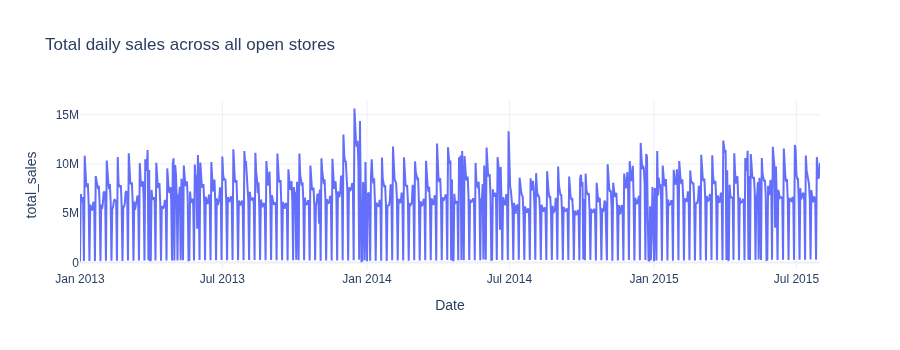

In [6]:
train_open = train[train["Open"] == 1].copy()
print(train_open["Sales"].describe())

daily = train_open.groupby("Date").agg(total_sales=("Sales", "sum"),
                                        total_customers=("Customers", "sum"),
                                        n_open_stores=("Store", "nunique")).reset_index()

fig = px.line(daily, x="Date", y="total_sales", title="Total daily sales across all open stores")
fig.update_layout(height=350)
fig.show()

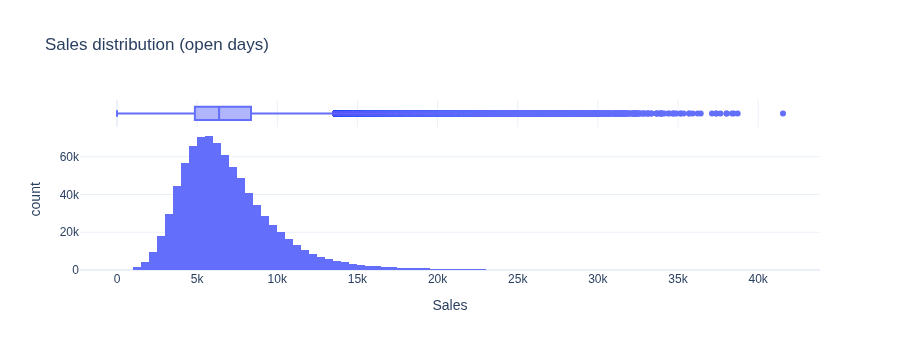

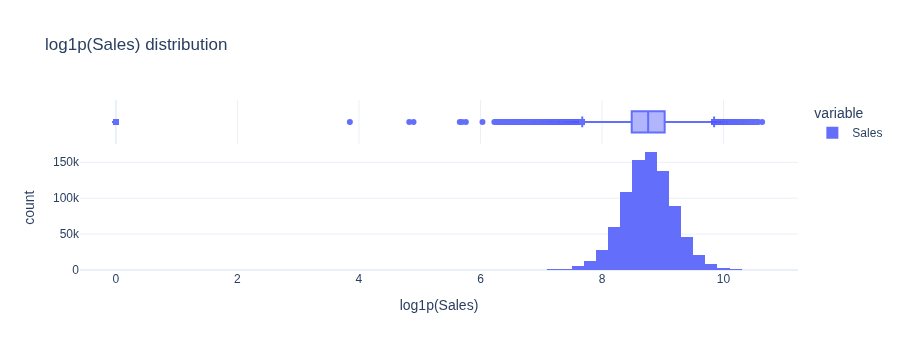

Sales skew: 1.5939220392699807 | log1p(Sales) skew: -0.6379710294195982


In [7]:
# RMSPE is a percentage-error metric -> variance grows with the size of Sales itself
# (right-skewed here). log1p(Sales) is far more symmetric, which is why Phase 2's
# linear model will train on the log scale instead of raw Sales.
fig = px.histogram(train_open, x="Sales", nbins=100, marginal="box", title="Sales distribution (open days)")
fig.update_layout(height=350)
fig.show()

fig = px.histogram(np.log1p(train_open["Sales"]), nbins=100, marginal="box",
                    title="log1p(Sales) distribution")
fig.update_layout(height=350, xaxis_title="log1p(Sales)")
fig.show()

print("Sales skew:", train_open["Sales"].skew(), "| log1p(Sales) skew:", np.log1p(train_open["Sales"]).skew())

Mean sales by day of week (1=Mon..7=Sun):
                   mean   count
DayOfWeek                     
1          8216.073074  137560
2          7088.113656  143961
3          6728.122978  141936
4          6767.310159  134644
5          7072.677012  138640
6          5874.840238  144058
7          8224.723908    3593

Mean sales by Promo:
               mean   count
Promo                     
0      5929.407603  467496
1      8228.281239  376896

Mean sales by StateHoliday:
                      mean   count
StateHoliday                     
0             6953.515034  843482
a             8487.471182     694
b             9887.889655     145
c             9743.746479      71

Mean sales by SchoolHoliday:
                       mean   count
SchoolHoliday                     
0              6896.782411  680935
1              7200.181650  163457


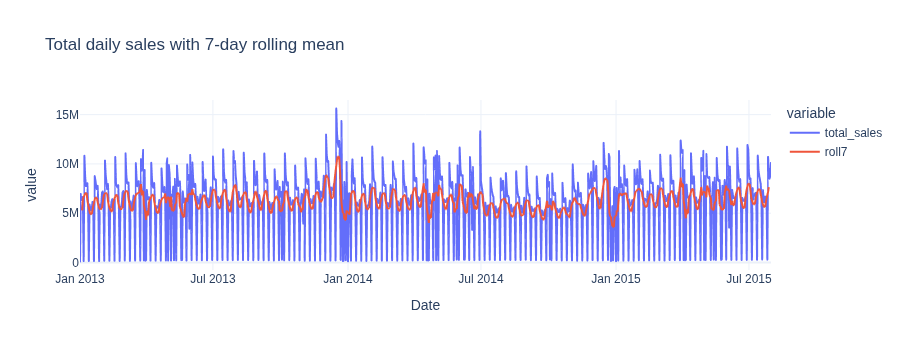

In [8]:
dow_stats = train_open.groupby("DayOfWeek")["Sales"].agg(["mean", "count"])
print("Mean sales by day of week (1=Mon..7=Sun):\n", dow_stats)

for col in ["Promo", "StateHoliday", "SchoolHoliday"]:
    print(f"\nMean sales by {col}:\n", train_open.groupby(col)["Sales"].agg(["mean", "count"]))

daily["dow"] = daily["Date"].dt.dayofweek
daily["roll7"] = daily["total_sales"].rolling(7, center=True).mean()
fig = px.line(daily, x="Date", y=["total_sales", "roll7"], title="Total daily sales with 7-day rolling mean")
fig.update_layout(height=350)
fig.show()

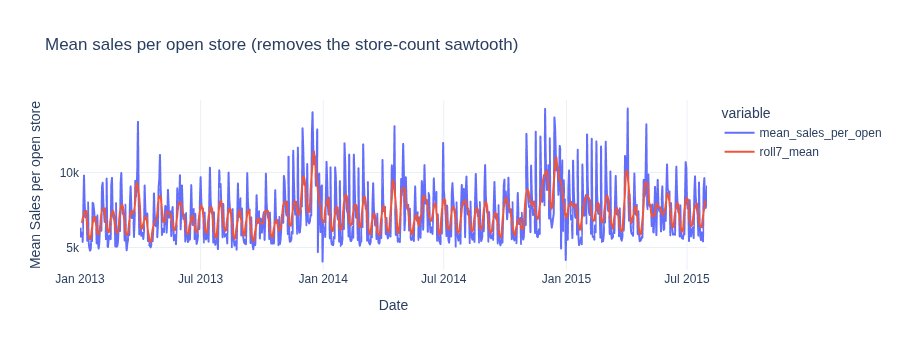

In [9]:
# The total_sales chart above is dominated by a weekly sawtooth from store-count
# swings (most stores close Sunday), not by actual demand. Normalizing by how many
# stores were open removes that artifact and reveals real demand shocks (holidays etc).
daily["mean_sales_per_open"] = daily["total_sales"] / daily["n_open_stores"]
daily["roll7_mean"] = daily["mean_sales_per_open"].rolling(7, center=True).mean()
fig = px.line(daily, x="Date", y=["mean_sales_per_open", "roll7_mean"],
              title="Mean sales per open store (removes the store-count sawtooth)")
fig.update_layout(height=350, yaxis_title="Mean Sales per open store")
fig.show()

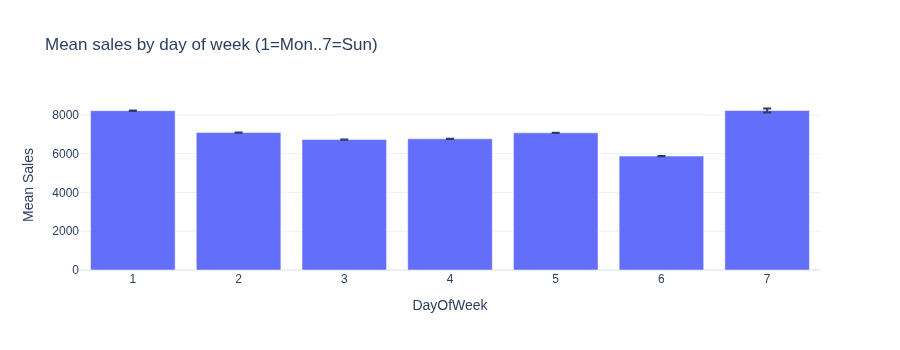

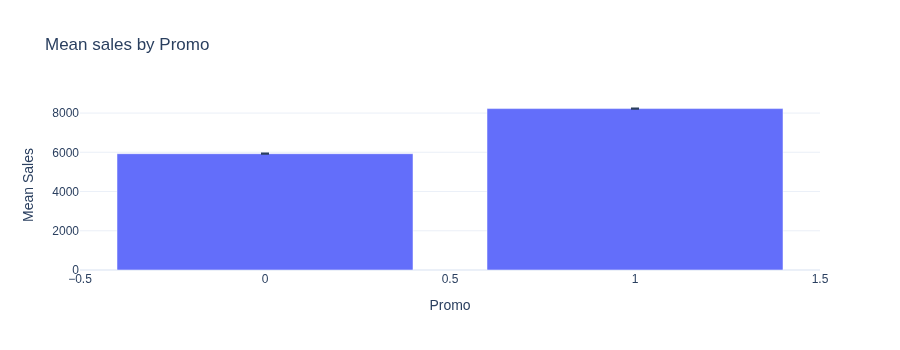

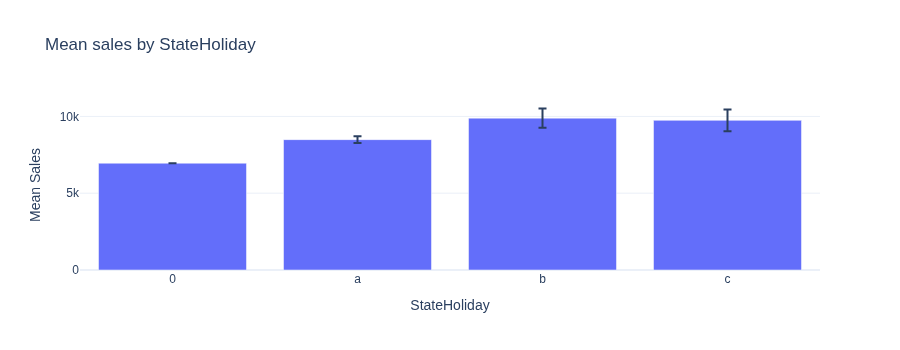

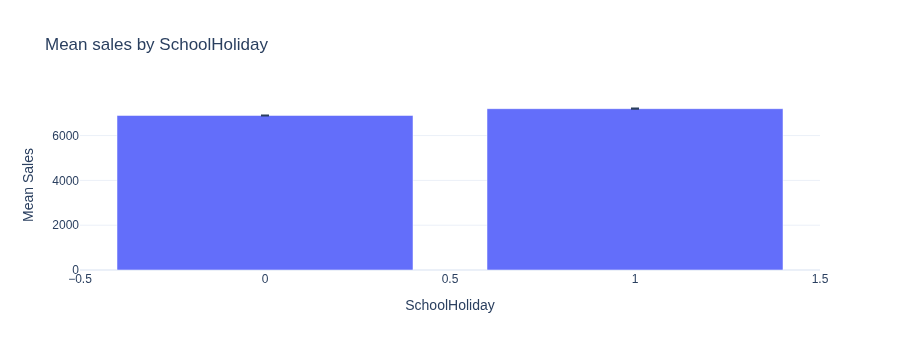

In [10]:
def bar_by(df, col, title):
    # error_y takes the column's values literally as +/- bar magnitude, so passing the
    # raw std would plot population spread (~3,100) rather than uncertainty in the mean.
    # With our sample sizes (tens/hundreds of thousands per group) the SEM is what's
    # actually relevant for judging whether groups differ.
    g = df.groupby(col)["Sales"].agg(mean="mean", std="std", n="count").reset_index()
    g["sem"] = g["std"] / np.sqrt(g["n"])
    fig = px.bar(g, x=col, y="mean", error_y="sem", hover_data=["n", "std"], title=title)
    fig.update_layout(height=350, yaxis_title="Mean Sales")
    fig.show()

bar_by(train_open, "DayOfWeek", "Mean sales by day of week (1=Mon..7=Sun)")
bar_by(train_open, "Promo", "Mean sales by Promo")
bar_by(train_open, "StateHoliday", "Mean sales by StateHoliday")
bar_by(train_open, "SchoolHoliday", "Mean sales by SchoolHoliday")

**Findings:** `Promo` gives a clear ~39% lift (8228 vs 5929 mean sales). Sunday (`DayOfWeek==7`) has only 3,593 open-rows (most stores close Sundays) yet the *highest* mean sales — likely selection bias (only certain, probably high-traffic, stores open Sundays), not a genuine "Sundays sell more" effect. Same pattern for `StateHoliday` a/b/c: stores open on a holiday sell *more* than a regular day, again likely because only select stores choose to open then. Checking the Sunday hypothesis directly below before trusting it.

In [11]:
sunday_stores = train_open.loc[train_open["DayOfWeek"] == 7, "Store"].unique()
print("n stores ever open on Sunday:", len(sunday_stores))

weekday_mask = train_open["DayOfWeek"] < 6
print("\nMean weekday (Mon-Fri) sales, Sunday-opening stores vs rest:")
print(train_open[weekday_mask].groupby(train_open["Store"].isin(sunday_stores))["Sales"].mean())

n stores ever open on Sunday: 33

Mean weekday (Mon-Fri) sales, Sunday-opening stores vs rest:
Store
False    7121.405438
True     8758.947883
Name: Sales, dtype: float64


Confirmed: only 33 of 1,115 stores ever open on Sunday, and those same stores also out-sell the rest on weekdays (8,759 vs 7,121). So "Sunday = higher sales" is a **store identity effect**, not a real day-of-week effect — `DayOfWeek` alone would mislead a model here; a per-store baseline/embedding is needed to absorb this. Same logic applies to the `StateHoliday` a/b/c result. Moving to store-level heterogeneity next.

In [12]:
# Who ARE the 33 Sunday-opening stores? Cross-check against StoreType/Assortment.
storeb = store.loc[store["StoreType"] == "b", "Store"]
print(f"StoreType b stores: {len(storeb)}, of which open on Sunday: {storeb.isin(sunday_stores).sum()}")
print("\nStoreType of the 33 Sunday-opening stores:\n", store.loc[store["Store"].isin(sunday_stores), "StoreType"].value_counts())
print("\nStoreType x Assortment crosstab:\n", pd.crosstab(store["StoreType"], store["Assortment"]))

StoreType b stores: 17, of which open on Sunday: 17

StoreType of the 33 Sunday-opening stores:
 StoreType
b    17
a    13
d     3
Name: count, dtype: int64

StoreType x Assortment crosstab:
 Assortment    a  b    c
StoreType              
a           381  0  221
b             7  9    1
c            77  0   71
d           128  0  220


**Ties the Sunday finding to a concrete store segment:** all 17 `StoreType b` stores open on Sundays (they're 17 of the 33) — `StoreType b` looks like a distinct business model (higher traffic, transit-hub-style locations), not a random subset. `Assortment b` is also exclusive to `StoreType b` (9 of its 17 stores) — so `StoreType` and `Assortment` aren't independent, worth remembering when encoding them as features.

In [13]:
merged = train_open.merge(store, on="Store", how="left")

print("Mean sales by StoreType:\n", merged.groupby("StoreType")["Sales"].agg(["mean", "count"]))
print("\nMean sales by Assortment:\n", merged.groupby("Assortment")["Sales"].agg(["mean", "count"]))

per_store = merged.groupby("Store")["Sales"].mean()
print("\nPer-store mean sales spread: min={:.0f}, median={:.0f}, max={:.0f}, std={:.0f}".format(
    per_store.min(), per_store.median(), per_store.max(), per_store.std()))

Mean sales by StoreType:
                    mean   count
StoreType                      
a           6925.167661  457077
b          10231.407505   15563
c           6932.512755  112978
d           6822.141881  258774

Mean sales by Assortment:
                    mean   count
Assortment                     
a           6621.017039  444909
b           8639.346322    8212
c           7300.526339  391271

Per-store mean sales spread: min=2704, median=6590, max=21757, std=2384


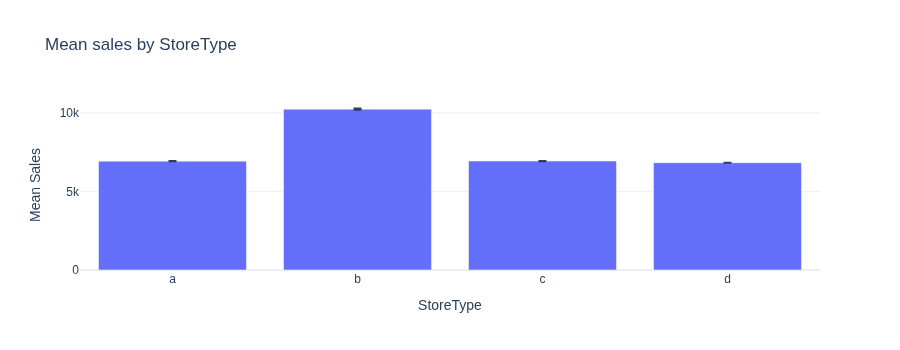

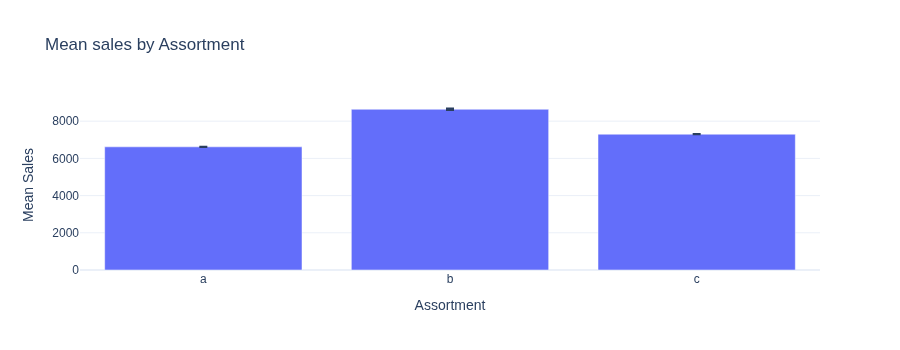

In [14]:
bar_by(merged, "StoreType", "Mean sales by StoreType")
bar_by(merged, "Assortment", "Mean sales by Assortment")

In [15]:
# Quintiles must be computed on store.csv (1 row/store), not on `merged` (1 row/
# transaction) -- binning transaction-level data weights the boundaries by how many
# days each store happened to be open, which isn't the quantity we're bucketing.
store["CompDistBin"] = pd.qcut(store["CompetitionDistance"], 5, duplicates="drop",
    labels=["Q1 closest", "Q2", "Q3", "Q4", "Q5 farthest"])
merged = merged.merge(store[["Store", "CompDistBin"]], on="Store", how="left")
print("Mean sales by CompetitionDistance quintile (binned at store level):\n",
      merged.groupby("CompDistBin", observed=True)["Sales"].agg(["mean", "count"]))

merged["year"] = merged["Date"].dt.year
merged["month"] = merged["Date"].dt.month
monthly = merged.groupby(["year", "month"])["Sales"].mean().unstack("month")
print("\nMean sales by year x month:\n", monthly.round(0))

Mean sales by CompetitionDistance quintile (binned at store level):
                     mean   count
CompDistBin                     
Q1 closest   7582.657394  172472
Q2           6846.972056  166691
Q3           6714.167525  165695
Q4           6810.351167  167456
Q5 farthest  6822.769383  169892

Mean sales by year x month:
 month      1       2       3       4       5       6       7       8       9   \
year                                                                            
2013   6240.0  6429.0  7213.0  6579.0  7076.0  6467.0  6923.0  6596.0  6363.0   
2014   6539.0  6678.0  6654.0  7227.0  6948.0  7251.0  6891.0  6714.0  6757.0   
2015   6913.0  6660.0  7071.0  7349.0  7308.0  7296.0  7033.0     NaN     NaN   

month      10      11      12  
year                           
2013   6473.0  6905.0  8613.0  
2014   6757.0  7540.0  8604.0  
2015      NaN     NaN     NaN  


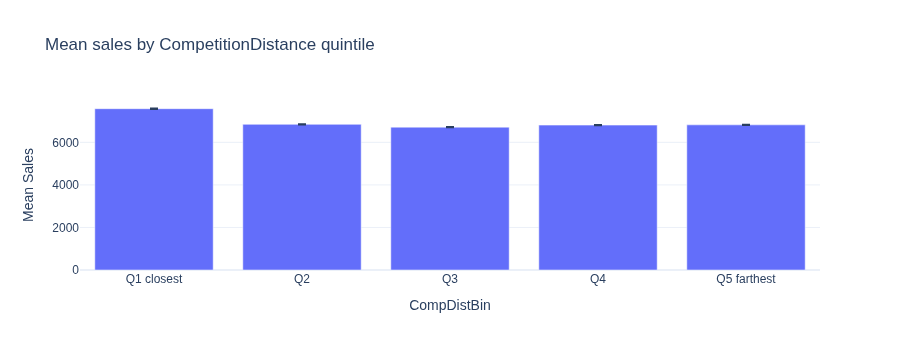

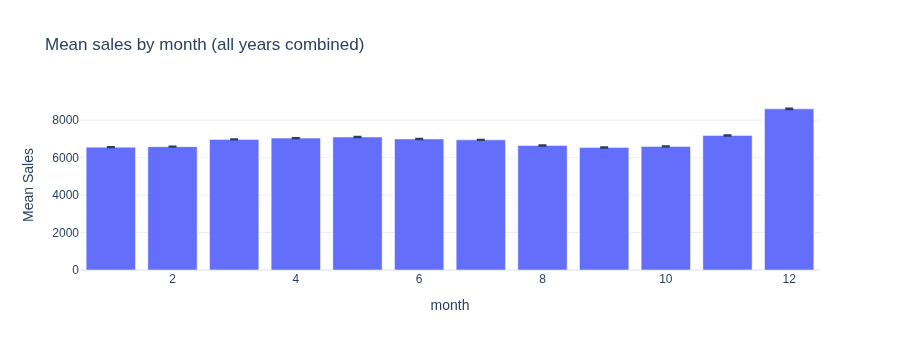

In [16]:
bar_by(merged, "CompDistBin", "Mean sales by CompetitionDistance quintile")
bar_by(merged, "month", "Mean sales by month (all years combined)")

**Leakage callout:** `Customers` lives in `train.csv` but is *not* in `test.csv` — it can't be used as a direct input feature for forecasting, only for exploration (e.g. decomposing Sales into traffic x basket size below). The assignment explicitly warns about fields that exist historically but aren't known for future dates; this is the clearest example in the dataset.

Sales = Customers x BasketSize, by StoreType:
              mean_sales  mean_customers  mean_basket  n_stores
StoreType                                                     
a           6925.167661      795.361469     8.846277       602
b          10231.407505     2021.822335     5.133097        17
c           6932.512755      815.465887     8.626227       148
d           6822.141881      606.339876    11.277862       348

Promo lift: customers +21.2%, basket size +13.8%


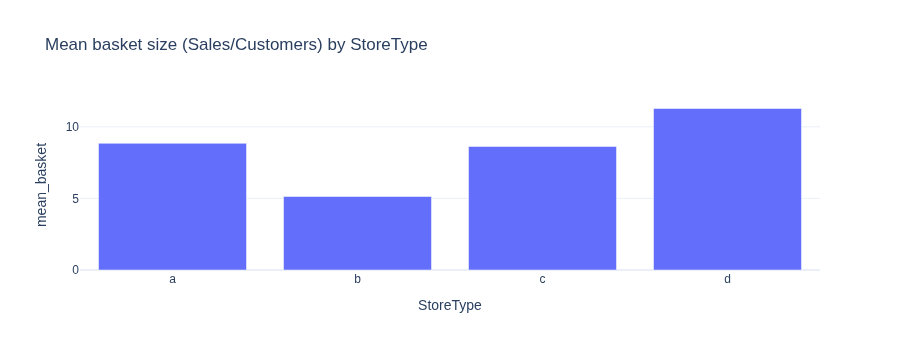

In [17]:
merged["BasketSize"] = merged["Sales"] / merged["Customers"]

profile = merged.groupby("StoreType").agg(mean_sales=("Sales", "mean"),
                                           mean_customers=("Customers", "mean"),
                                           mean_basket=("BasketSize", "mean"),
                                           n_stores=("Store", "nunique"))
print("Sales = Customers x BasketSize, by StoreType:\n", profile)

promo_profile = merged.groupby("Promo").agg(mean_customers=("Customers", "mean"), mean_basket=("BasketSize", "mean"))
lift = (promo_profile.loc[1] / promo_profile.loc[0] - 1) * 100
print("\nPromo lift: customers +{:.1f}%, basket size +{:.1f}%".format(lift["mean_customers"], lift["mean_basket"]))

fig = px.bar(profile.reset_index(), x="StoreType", y="mean_basket", title="Mean basket size (Sales/Customers) by StoreType")
fig.update_layout(height=350)
fig.show()

In [18]:
# Light check: for stores whose competitor opened mid-window (2013-2015), does their
# own sales trend shift after that date? A crude before/after per-store comparison --
# not causal (doesn't control for the overall upward trend seen above), just a sanity look.
comp_opened = store.dropna(subset=["CompetitionOpenSinceYear", "CompetitionOpenSinceMonth"]).copy()
comp_opened["comp_open_date"] = pd.to_datetime(
    comp_opened["CompetitionOpenSinceYear"].astype(int).astype(str) + "-" +
    comp_opened["CompetitionOpenSinceMonth"].astype(int).astype(str) + "-01")
mid_window = comp_opened[(comp_opened["comp_open_date"] >= "2013-06-01") & (comp_opened["comp_open_date"] <= "2015-01-31")]
print(f"{len(mid_window)} stores had a new competitor open during 2013-2015")

rows = []
for _, r in mid_window.iterrows():
    s_sales = train_open.loc[train_open["Store"] == r["Store"], ["Date", "Sales"]]
    before = s_sales.loc[s_sales["Date"] < r["comp_open_date"], "Sales"].mean()
    after = s_sales.loc[s_sales["Date"] >= r["comp_open_date"], "Sales"].mean()
    if pd.notna(before) and pd.notna(after):
        rows.append(after / before - 1)
print(f"mean sales change after competitor opens: {np.mean(rows)*100:.1f}% (n={len(rows)} stores)")
print("(compare to the ~5-10%/yr organic upward trend already seen in the monthly table -- "
      "this is not a clean causal estimate, just a directional check)")

121 stores had a new competitor open during 2013-2015


mean sales change after competitor opens: -3.6% (n=121 stores)
(compare to the ~5-10%/yr organic upward trend already seen in the monthly table -- this is not a clean causal estimate, just a directional check)


Sales are on average ~3.6% *lower* after a new competitor opens, against a backdrop of ~5-10%/year organic growth over the same period — so relative to what these stores "should" have done absent competition, this points to a real negative effect, unlike the static `CompetitionDistance` quintile result (which is confounded by urban-location selection). Not a rigorous causal estimate (no control group, no trend adjustment), but a more convincing signal than the static distance comparison — worth a proper before/after-with-trend-control version if competition features matter to the final model.

## Summary & implications for modeling

**Patterns found:**
- Strong per-store heterogeneity dominates everything else (mean sales range 2,704–21,757 across stores) — store identity must be in the model (per-store features, target encoding, or embeddings), not left implicit.
- Apparent "day-of-week" and "state-holiday" effects are actually **store-selection confounds**: only a minority of stores open on Sundays/holidays, and those are structurally higher-selling stores — specifically, all 17 `StoreType b` stores (a distinct, higher-traffic business model) account for half of the 33 Sunday-opening stores. Same logic applies to `CompetitionDistance` (binned at the store level): the closest-competitor quintile still sells more, almost certainly a marker of busy urban locations rather than competition helping. A separate, cruder before/after check around actual competitor-opening events points the other way (~3.6% relative decline vs. trend) — the static distance confound and the dynamic opening-event effect aren't the same claim, and only the latter looks like a real causal signal.
- `Promo` has a clean, direct ~39% lift, decomposable into +21% customers and +14% basket size (`Sales = Customers x BasketSize`, though `Customers` itself is **not available in `test.csv`** and can't be used as a model input).
- Clear yearly seasonality: December spikes ~25-30% above baseline (Christmas), plus a mild year-over-year upward trend — visible cleanly once the daily-total chart is normalized by open-store count (the raw total is dominated by a weekly sawtooth from store closures, not demand).
- `Sales` is right-skewed (skew 1.59); `log1p(Sales)` is close to symmetric (skew -0.64) — supports training on the log scale later, consistent with RMSPE being a percentage-error metric.
- Data quality: no nulls/duplicates in `train.csv`; `StateHoliday` explicitly cast to `str` on read. `store.csv` missingness is structural (`Promo2Since*`/`PromoInterval` null exactly when `Promo2==0`). 181 of 1,115 stores have an identical ~6-month reporting gap (2014-07-01 to 2014-12-31). Test period has 11 `Open` nulls to impute.

**Implications:**
- Validation must be time-based (last ~6 weeks of train) — confirmed the assignment's instinct, no surprises here.
- Baseline should be per-store (or per-store x day-of-week), not global, given the heterogeneity above.
- Feature engineering should let the model use store-level context, not raw calendar fields in isolation, and must special-case the 181 gap stores for any lag/rolling feature.
- `Customers` is exploration-only — never a model input, since it doesn't exist in `test.csv`.

Next: [rossmann_baseline.ipynb](rossmann_baseline.ipynb) — Phase 1, time-based validation split + naive baselines.